# TP2 - Valores Faltantes
Materia: Diseño de Bases de Datos II  
Carrera: Ingeniería en Informática - Universidad de Mendoza  
Alumno: Francisco Rodeles  


# Ejercicio 1: Dataset de Esponjas Marinas (Demospongiae.Porifera)

- Leer y obtener el siguiente dataset sobre <a href="https://archive.ics.uci.edu/ml/datasets/Sponge">esponjas</a>
- Analizar la naturaleza y distribución de los datos faltantes
- Seleccionar e implementar el mejor método para tratar los datos faltantes
- Justificar la elección articulando con las pautas de limpieza de datos y prevención de sesgos


## 1. Importación de Librerías y Configuración

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 2. Definición de Atributos y Carga del Dataset (Esponjas)

A partir del archivo de metadatos sponge.info:
- El dataset cuenta con 76 instancias (especies de esponjas marinas) y 45 atributos taxonómicos, precedidos por el identificador de especie.
- Los valores faltantes están codificados con el carácter interrogante ('?').
- Se especifica header=None, la lista completa de names=columnas y na_values='?' para evitar consumir la primera fila como cabecera y garantizar la detección real de nulos.


In [2]:
columnas_esponjas = [
    'ESPECIE',
    'A.CAPAS_DEL_CORTEX',
    'A.CAPA_INTERNA_DEL_CORTEX',
    'A.CORTEX',
    'A.CORTEX_FIBROSO',
    'A.CORTEX_SOLO_DE_ESPICULAS_TANGENCIALES',
    'A.CUERPOS_EXTRANOS_EN_EL_CORTEX',
    'A.GROSOR_DEL_CORTEX',
    'A.HACES_DE_ESPICULAS_PRINCIPALES_EN_POMPON_EN_EL_CORTEX',
    'A.TILOSTILOS_ADICIONALES_COANOSOMA',
    'B.NUMERO_DE_TIPOS_DE_MEGASCLERAS',
    'C.TIPO_ESPICULA_PRINCIPAL_DIACTINA_TUBERCULADA',
    'C.TIPO_ESPICULA_PRINCIPAL_ESTILO',
    'C.TIPO_ESPICULA_PRINCIPAL_ESTILOS_2_TAMANOS',
    'C.TIPO_ESPICULA_PRINCIPAL_ESTILO_TILOSTILO',
    'C.TIPO_ESPICULA_PRINCIPAL_ESTRONGILOXA',
    'C.TIPO_ESPICULA_PRINCIPAL_OXAS',
    'C.TIPO_ESPICULA_PRINCIPAL_TILOSTILO',
    'D.ESPICULA_PRINCIPAL_ESTILO',
    'D.ESPICULA_PRINCIPAL_TILOSTILO',
    'D.FORMA_BASE_TILOSTILO_PRINCIPAL',
    'E.DISPOSICION_MEGASCLERAS_ECTOSOMICAS_EN_EL_ECTOSOMA',
    'E.FORMA_BASE_TILOSTILO_ECTOSOMICO',
    'E.FORMA_MEGASCLERA_ECTOSOMICA',
    'E.TIPO_MEGASCLERA_ECTOSOMICA',
    'F.TIPO_DE_EXOSTILO',
    'G.FORMA_MEGASCLERA_INTERMEDIARIA',
    'G.TIPO_MEGASCLERA_INTERMEDIARIA',
    'H.LONGITUD_MEGASCLERAS',
    'I.MICROSCLERAS',
    'I.TIPO_MICROSCLERA',
    'J.ASTER',
    'J.DIAMETRO_ESFERASTER',
    'J.TIPO_DE_ASTER',
    'J.TIPO_DE_DIPLASTER',
    'J.TIPO_DE_ESFERASTER',
    'K.FORMA_FINAL',
    'L.NUMERO_DE_PAPILAS',
    'L.PAPILAS',
    'M.COLOR',
    'N.SUPERFICIE',
    'O.DISPOSICION_ESPICULAR_ESQUELETO',
    'P.ALOJA_CANGREJO_ERMITANO',
    'P.PERFORANTE',
    'P.PSEUDORAICES',
    'P.SUSTRATO'
]

# Carga del dataset con tratamiento explícito del símbolo '?' como NaN
df_sponge = pd.read_csv('../data/sponge.data', header=None, names=columnas_esponjas, na_values='?')
df_sponge.head()


,ESPECIE,A.CAPAS_DEL_CORTEX,A.CAPA_INTERNA_DEL_CORTEX,A.CORTEX,A.CORTEX_FIBROSO,A.CORTEX_SOLO_DE_ESPICULAS_TANGENCIALES,A.CUERPOS_EXTRANOS_EN_EL_CORTEX,A.GROSOR_DEL_CORTEX,A.HACES_DE_ESPICULAS_PRINCIPALES_EN_POMPON_EN_EL_CORTEX,A.TILOSTILOS_ADICIONALES_COANOSOMA,...,K.FORMA_FINAL,L.NUMERO_DE_PAPILAS,L.PAPILAS,M.COLOR,N.SUPERFICIE,O.DISPOSICION_ESPICULAR_ESQUELETO,P.ALOJA_CANGREJO_ERMITANO,P.PERFORANTE,P.PSEUDORAICES,P.SUSTRATO
0,AAPTOS_AAPTOS,1_CAPA,SIN_CAPA_INTERNA_DEL_CORTEX,SI,NO,NO,NO,3,NO,SIN_TILOSTILOS_ADICIONALES,...,MASIVO_IRREGULAR,0,NO,OTROS,RUGOSA,RADIAL,NO,NO,NO,DURO
1,ALECTONA_MILLARI,SIN_CORTEX,SIN_CAPA_INTERNA_DEL_CORTEX,NO,SIN_CORTEX,SIN_CORTEX,SIN_CORTEX,0,NO,SIN_TILOSTILOS_ADICIONALES,...,INCRUSTANTE,0,NO,NaN,LISA,CONFUSA,NO,SI,NO,DURO
2,CLIONA_CARTERI,SIN_CORTEX,SIN_CAPA_INTERNA_DEL_CORTEX,NO,SIN_CORTEX,SIN_CORTEX,SIN_CORTEX,0,NO,SIN_TILOSTILOS_ADICIONALES,...,INCRUSTANTE,1,SI,OTROS,LISA,CONFUSA,NO,SI,NO,DURO
3,CLIONA_CELATA,SIN_CORTEX,SIN_CAPA_INTERNA_DEL_CORTEX,NO,SIN_CORTEX,SIN_CORTEX,SIN_CORTEX,0,NO,SIN_TILOSTILOS_ADICIONALES,...,MASIVO_IRREGULAR,3,SI,OTROS,LISA,CONFUSA,NO,SI,NO,DURO
4,CLIONA_LABYRINTHICA,SIN_CORTEX,SIN_CAPA_INTERNA_DEL_CORTEX,NO,SIN_CORTEX,SIN_CORTEX,SIN_CORTEX,0,NO,SIN_TILOSTILOS_ADICIONALES,...,INCRUSTANTE,0,NO,OTROS,LISA,CONFUSA,NO,SI,NO,DURO


## 3. Exploración de Dimensiones y Tipos de Datos (Esponjas)

In [3]:
print(f"Dimensiones del dataset de esponjas: {df_sponge.shape[0]} instancias x {df_sponge.shape[1]} columnas")
df_sponge.info()


Dimensiones del dataset de esponjas: 76 instancias x 46 columnas
<class 'pandas.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 46 columns):
 #   Column                                                   Non-Null Count  Dtype
---  ------                                                   --------------  -----
 0   ESPECIE                                                  76 non-null     str  
 1   A.CAPAS_DEL_CORTEX                                       76 non-null     str  
 2   A.CAPA_INTERNA_DEL_CORTEX                                76 non-null     str  
 3   A.CORTEX                                                 76 non-null     str  
 4   A.CORTEX_FIBROSO                                         76 non-null     str  
 5   A.CORTEX_SOLO_DE_ESPICULAS_TANGENCIALES                  76 non-null     str  
 6   A.CUERPOS_EXTRANOS_EN_EL_CORTEX                          76 non-null     str  
 7   A.GROSOR_DEL_CORTEX                                      76 non-null     int64
 8 

## 4. Auditoría y Análisis de la Naturaleza y Distribución de los Datos Faltantes

In [4]:
faltantes_sponge = []
for columna in df_sponge.columns:
    atributo = {}
    atributo["columna"] = columna
    atributo["porcentaje"] = np.mean(df_sponge[columna].isnull()) * 100
    atributo["cantidad"] = np.sum(df_sponge[columna].isnull())
    faltantes_sponge.append(atributo)  

faltantes_sponge_df = pd.DataFrame(faltantes_sponge).sort_values('cantidad', ascending=False)
df_sponge_con_nulos = faltantes_sponge_df[faltantes_sponge_df['cantidad'] > 0]
display(df_sponge_con_nulos)


,columna,porcentaje,cantidad
39,M.COLOR,28.947368,22


### Visualización Gráfica de los Datos Faltantes (Esponjas)

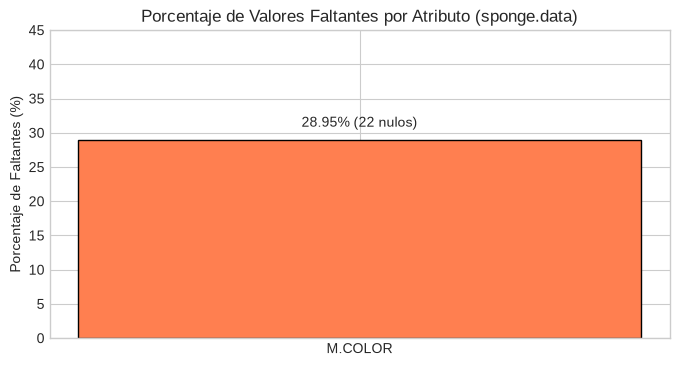

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(df_sponge_con_nulos["columna"], df_sponge_con_nulos["porcentaje"], color='coral', edgecolor='black', width=0.4)
ax.set_ylabel('Porcentaje de Faltantes (%)')
ax.set_title('Porcentaje de Valores Faltantes por Atributo (sponge.data)')
ax.set_ylim(0, 45)

for b, cant in zip(barras, df_sponge_con_nulos["cantidad"]):
    yval = b.get_height()
    ax.text(b.get_x() + b.get_width()/2.0, yval + 1.5, f"{yval:.2f}% ({cant} nulos)", ha='center', va='bottom')

plt.show()


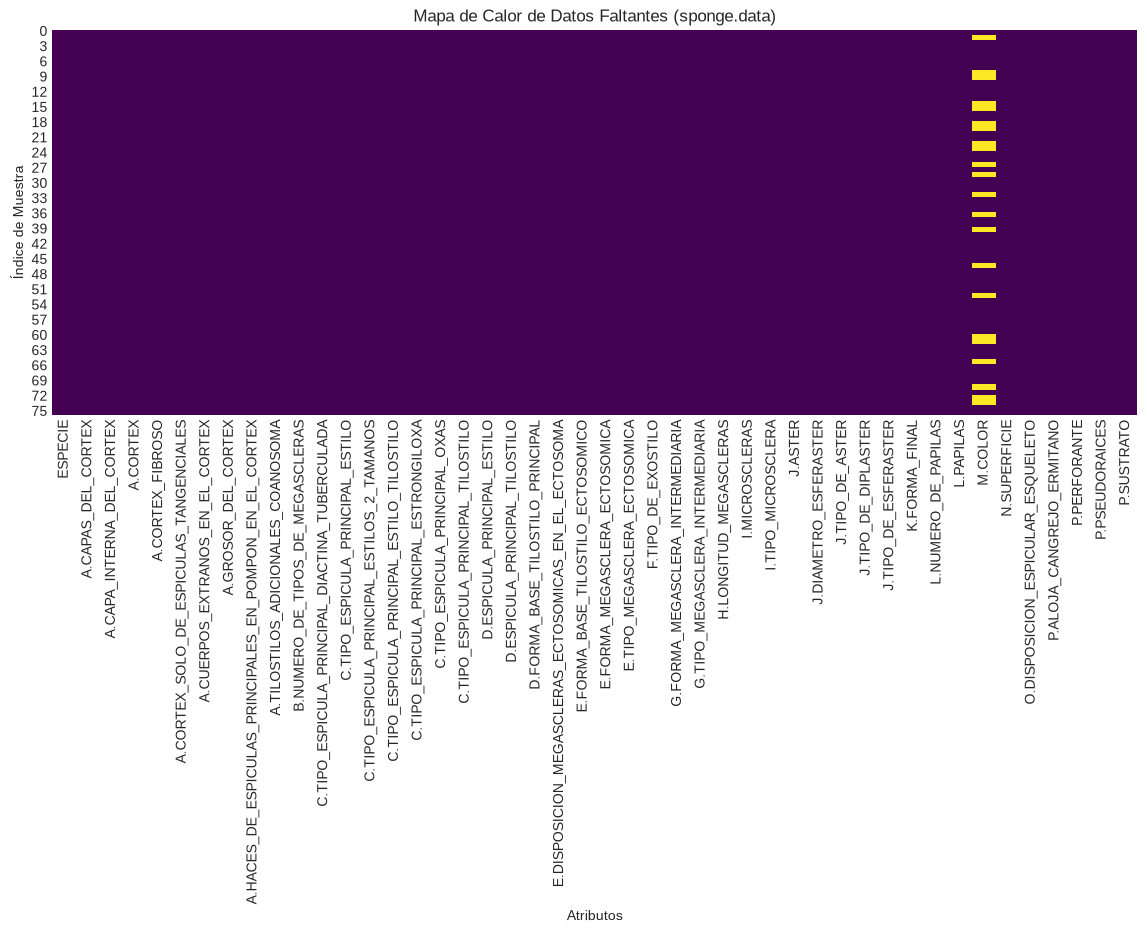

In [6]:
plt.figure(figsize=(14, 5))
sns.heatmap(df_sponge.isnull(), cbar=False, cmap='viridis')
plt.title('Mapa de Calor de Datos Faltantes (sponge.data)')
plt.xlabel('Atributos')
plt.ylabel('Índice de Muestra')
plt.show()


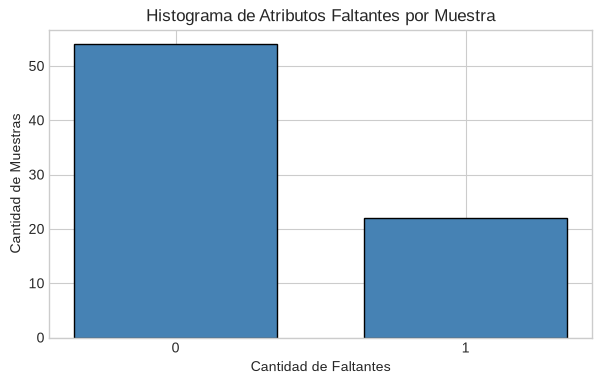

Muestras con 0 faltantes: 54 (71.05%)
Muestras con 1 faltante:  22 (28.95%)


In [7]:
df_sponge_hist = df_sponge.copy()
for col in df_sponge.columns:
    faltan = df_sponge[col].isnull()
    if np.sum(faltan) > 0:
        df_sponge_hist[col + "_faltante"] = faltan

cols_indicadoras = [c for c in df_sponge_hist.columns if '_faltante' in c]
df_sponge_hist['cant_falt'] = df_sponge_hist[cols_indicadoras].sum(axis=1)

plt.figure(figsize=(7, 4))
plt.hist(df_sponge_hist['cant_falt'], bins=[-0.5, 0.5, 1.5], rwidth=0.7, color='steelblue', edgecolor='black')
plt.ylabel('Cantidad de Muestras')
plt.xlabel('Cantidad de Faltantes')
plt.title('Histograma de Atributos Faltantes por Muestra')
plt.xticks([0, 1])
plt.show()

print(f"Muestras con 0 faltantes: {(df_sponge_hist['cant_falt'] == 0).sum()} ({(df_sponge_hist['cant_falt'] == 0).mean()*100:.2f}%)")
print(f"Muestras con 1 faltante:  {(df_sponge_hist['cant_falt'] == 1).sum()} ({(df_sponge_hist['cant_falt'] == 1).mean()*100:.2f}%)")


## 5. Inspección del Atributo M.COLOR

In [8]:
print("Frecuencias de 'M.COLOR' (incluyendo nulos):")
display(df_sponge['M.COLOR'].value_counts(dropna=False))


Frecuencias de 'M.COLOR' (incluyendo nulos):


M.COLOR
OTROS                         36
NaN                           22
AMARILLO_PALIDO               17
AZUL_O_ANARANJADO_INTENSOS     1
Name: count, dtype: int64

## 6. Selección e Implementación del Método de Tratamiento (Esponjas)

### Evaluación de Técnicas (Metodología de Cátedra y Prevención de Sesgos):

1. Eliminar Muestras (dropna):
   - Eliminar las 22 tuplas con datos faltantes reduciría el dataset de 76 a 54 instancias (una pérdida del 28.95%).
   - Según el apunte SesgosOBias.pdf, esta reducción drástica introduce un sesgo de selección, ya que se descarta casi un tercio de las especies del estudio y se altera la representatividad de la muestra, destruyendo información válida en los otros 45 atributos morfológicos intactos. Por lo tanto, se descarta la eliminación de muestras.

2. Eliminar Atributos (drop de columna):
   - Eliminar M.COLOR provocaría la pérdida de la información de color disponible para el 71.05% de las especies. Solo se justificaría si el atributo fuese totalmente irrelevante para el análisis.

3. Reemplazo con la Moda (Técnica recomendada para variables categóricas):
   - Según el apunte Valores Faltantes.ipynb, al tratarse de un atributo cualitativo/nominal, el estadístico apropiado es la moda ('OTROS', con 36 ocurrencias).
   - Preserva el 100% de las muestras y es computacionalmente simple.

4. Uso de Constante Global / Categoría Explícita ('DESCONOCIDO'):
   - Imputar como 'DESCONOCIDO' permite retener todas las instancias sin sobreestimar la categoría modal 'OTROS'.


In [9]:
# Método 1: Imputación por Moda (Metodología recomendada por la Cátedra)
df_sponge_moda = df_sponge.copy()
moda_color = df_sponge_moda['M.COLOR'].describe()['top']
print(f"Moda calculada para M.COLOR: '{moda_color}'")

df_sponge_moda['M.COLOR'] = df_sponge_moda['M.COLOR'].fillna(moda_color)
print(f"Valores nulos en df_sponge_moda tras imputación: {df_sponge_moda.isnull().sum().sum()}")
display(df_sponge_moda['M.COLOR'].value_counts())


Moda calculada para M.COLOR: 'OTROS'
Valores nulos en df_sponge_moda tras imputación: 0


M.COLOR
OTROS                         58
AMARILLO_PALIDO               17
AZUL_O_ANARANJADO_INTENSOS     1
Name: count, dtype: int64

In [10]:
# Método 2: Imputación mediante Constante Global ('DESCONOCIDO')
df_sponge_global = df_sponge.copy()
df_sponge_global['M.COLOR'] = df_sponge_global['M.COLOR'].fillna('DESCONOCIDO')
print(f"Valores nulos en df_sponge_global tras imputación: {df_sponge_global.isnull().sum().sum()}")
display(df_sponge_global['M.COLOR'].value_counts())


Valores nulos en df_sponge_global tras imputación: 0


M.COLOR
OTROS                         36
DESCONOCIDO                   22
AMARILLO_PALIDO               17
AZUL_O_ANARANJADO_INTENSOS     1
Name: count, dtype: int64

### Comparación Gráfica Antes y Después del Tratamiento (Esponjas)

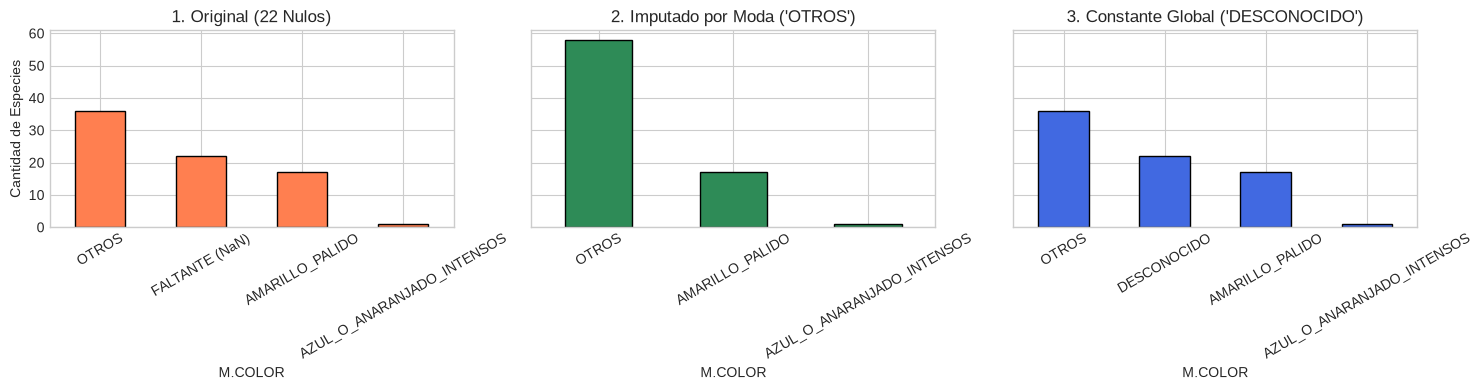

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# 1. Original con NaN
df_sponge['M.COLOR'].fillna('FALTANTE (NaN)').value_counts().plot(
    kind='bar', ax=axes[0], color='coral', edgecolor='black'
)
axes[0].set_title('1. Original (22 Nulos)')
axes[0].set_ylabel('Cantidad de Especies')
axes[0].tick_params(axis='x', rotation=30)

# 2. Imputado por Moda
df_sponge_moda['M.COLOR'].value_counts().plot(
    kind='bar', ax=axes[1], color='seagreen', edgecolor='black'
)
axes[1].set_title("2. Imputado por Moda ('OTROS')")
axes[1].tick_params(axis='x', rotation=30)

# 3. Imputado por Constante Global
df_sponge_global['M.COLOR'].value_counts().plot(
    kind='bar', ax=axes[2], color='royalblue', edgecolor='black'
)
axes[2].set_title("3. Constante Global ('DESCONOCIDO')")
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


## 7. Justificación de la Elección (Esponjas)

1. Naturaleza del Atributo:
   - La columna M.COLOR es un atributo nominal/categórico, por lo que no es matemáticamente válido aplicar medidas de tendencia central como la media o la mediana.
   - Es la única columna con datos incompletos en todo el conjunto de datos (las restantes 45 variables morfológicas y espiculares están completas al 100%).

2. Evitación del Sesgo de Selección (SesgosOBias.pdf):
   - Descartar tuplas con dropna() provocaría la eliminación del 28.95% del dataset (22 de 76 especies). En un estudio biológico taxonómico de escala reducida, esto causaría un sesgo de selección, comprometiendo la representatividad estadística y omitiendo especímenes que poseen información crucial en su arquitectura interna de espículas y córtex.

3. Conclusión Técnica:
   - Se selecciona como solución principal la imputación por moda ('OTROS'), cumpliendo con la regla de cátedra de reemplazo para variables categóricas, dejando disponible además la alternativa de constante global ('DESCONOCIDO') para aplicaciones donde convenga aislar explícitamente la falta de registro del espécimen.


---

# Ejercicio 2: Dataset de Ecocardiogramas (Supervivencia a Infarto de Miocardio)

- Leer y obtener el siguiente dataset sobre <a href="https://archive.ics.uci.edu/ml/datasets/Echocardiogram">ecocardiogramas</a>
- Analizar la naturaleza y distribución de los datos faltantes
- Seleccionar e implementar el mejor método para tratar los datos faltantes
- Justificar la elección


## 1. Contexto Clínico y Carga de Datos

A partir de la documentación médica de echocardiogram.names:
- El dataset contiene registros clínicos de 132 pacientes que sufrieron infarto agudo de miocardio.
- Consta de 13 atributos, que abarcan variables temporales de supervivencia, indicadores fisiológicos de contractilidad cardíaca (epss, fractional_shortening, lvdd), escalas de motilidad ventricular (wall_motion_score, wall_motion_index), metadatos y la variable objetivo alive_at_1 (si el paciente sobrevivió al menos 1 año tras el infarto).
- Los valores ausentes están representados por '?'.
- La fila 50 del archivo original contiene una anomalía estructural histórica de formato (14 campos en vez de 13 y 100% de nulos en variables clínicas), por lo que se utiliza on_bad_lines='skip' para ignorar dicha tupla corrupta.


In [12]:
cols_echo = [
    'survival',
    'still_alive',
    'age_at_heart_attack',
    'pericardial_effusion',
    'fractional_shortening',
    'epss',
    'lvdd',
    'wall_motion_score',
    'wall_motion_index',
    'mult',
    'name',
    'group',
    'alive_at_1'
]

# Carga de ecocardiogramas con reconocimiento de '?' como NaN
df_echo = pd.read_csv('../data/echocardiogram.data', header=None, names=cols_echo, na_values='?', on_bad_lines='skip')
print(f"Dimensiones del dataset cargado: {df_echo.shape[0]} pacientes x {df_echo.shape[1]} atributos")
df_echo.head()


Dimensiones del dataset cargado: 131 pacientes x 13 atributos


,survival,still_alive,age_at_heart_attack,pericardial_effusion,fractional_shortening,epss,lvdd,wall_motion_score,wall_motion_index,mult,name,group,alive_at_1
0,11.0,0,71.0,0,0.260,9.000,4.600,14.0,1.00,1.000,name,1.0,0.0
1,19.0,0,72.0,0,0.380,6.000,4.100,14.0,1.70,0.588,name,1.0,0.0
2,16.0,0,55.0,0,0.260,4.000,3.420,14.0,1.00,1.000,name,1.0,0.0
3,57.0,0,60.0,0,0.253,12.062,4.603,16.0,1.45,0.788,name,1.0,0.0
4,19.0,1,57.0,0,0.160,22.000,5.750,18.0,2.25,0.571,name,1.0,0.0


## 2. Dimensiones e Información de Tipos (Ecocardiogramas)

In [13]:
df_echo.info()
display(df_echo.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])


<class 'pandas.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   survival               130 non-null    float64
 1   still_alive            131 non-null    int64  
 2   age_at_heart_attack    126 non-null    float64
 3   pericardial_effusion   131 non-null    int64  
 4   fractional_shortening  124 non-null    float64
 5   epss                   117 non-null    float64
 6   lvdd                   121 non-null    float64
 7   wall_motion_score      128 non-null    float64
 8   wall_motion_index      130 non-null    float64
 9   mult                   128 non-null    float64
 10  name                   131 non-null    str    
 11  group                  109 non-null    float64
 12  alive_at_1             74 non-null     float64
dtypes: float64(10), int64(2), str(1)
memory usage: 13.4 KB


,count,mean,std,min,50%,max
survival,130.0,22.182923,15.858267,0.03,23.500,57.00
still_alive,131.0,0.328244,0.471377,0.00,0.000,1.00
age_at_heart_attack,126.0,62.813722,8.342110,35.00,62.000,86.00
pericardial_effusion,131.0,0.183206,0.388320,0.00,0.000,1.00
fractional_shortening,124.0,0.216734,0.107513,0.01,0.205,0.61
epss,117.0,12.164769,7.370159,0.00,11.000,40.00
lvdd,121.0,4.763157,0.810013,2.32,4.650,6.78
wall_motion_score,128.0,14.438125,5.018566,2.00,14.000,39.00
wall_motion_index,130.0,1.378000,0.451850,1.00,1.216,3.00
mult,128.0,0.776719,0.199078,0.14,0.786,2.00


## 3. Análisis de la Naturaleza y Distribución de los Datos Faltantes

In [14]:
faltantes_echo = []
for columna in df_echo.columns:
    item = {}
    item["columna"] = columna
    item["porcentaje"] = np.mean(df_echo[columna].isnull()) * 100
    item["cantidad"] = np.sum(df_echo[columna].isnull())
    faltantes_echo.append(item)

df_fl_echo = pd.DataFrame(faltantes_echo).sort_values('cantidad', ascending=False)
df_fl_echo_con_nulos = df_fl_echo[df_fl_echo['cantidad'] > 0]
display(df_fl_echo_con_nulos)


,columna,porcentaje,cantidad
12,alive_at_1,43.511450,57
11,group,16.793893,22
5,epss,10.687023,14
6,lvdd,7.633588,10
4,fractional_shortening,5.343511,7
2,age_at_heart_attack,3.816794,5
9,mult,2.290076,3
7,wall_motion_score,2.290076,3
0,survival,0.763359,1
8,wall_motion_index,0.763359,1


### Visualización Gráfica de los Datos Faltantes (Ecocardiogramas)

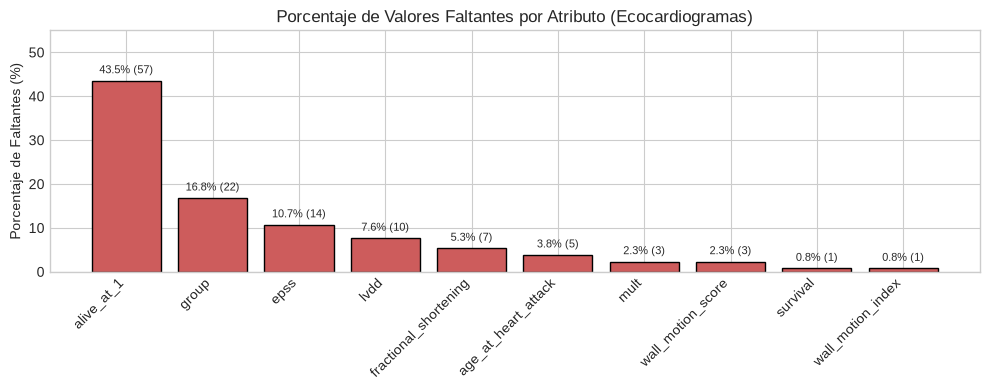

In [15]:
plt.figure(figsize=(10, 4))
barras = plt.bar(df_fl_echo_con_nulos["columna"], df_fl_echo_con_nulos["porcentaje"], color='indianred', edgecolor='black')
plt.ylabel('Porcentaje de Faltantes (%)')
plt.title('Porcentaje de Valores Faltantes por Atributo (Ecocardiogramas)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 55)

for b, cant in zip(barras, df_fl_echo_con_nulos["cantidad"]):
    yval = b.get_height()
    label = f"{yval:.1f}% ({cant})"
    plt.text(b.get_x() + b.get_width()/2.0, yval + 1.2, label, ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


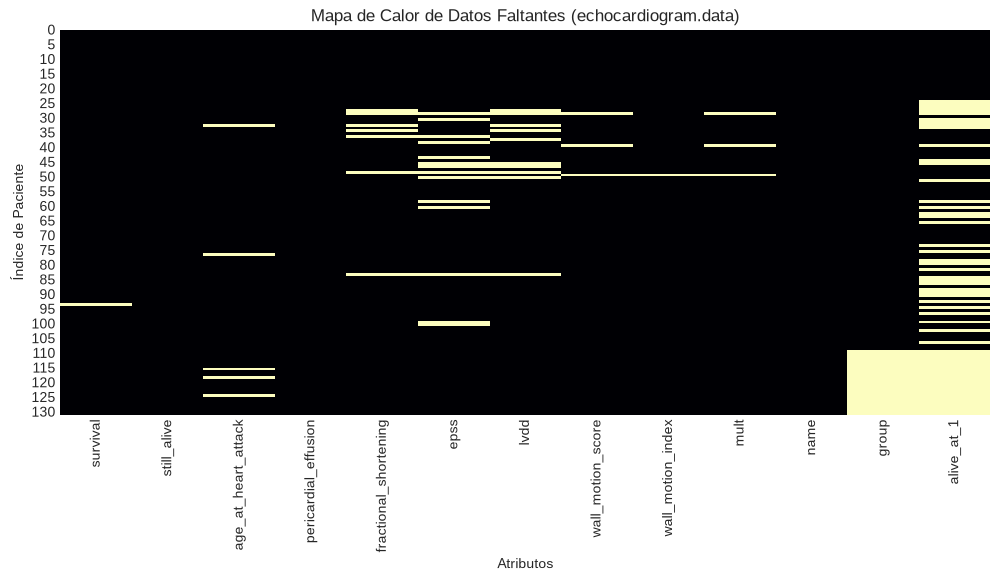

In [16]:
plt.figure(figsize=(12, 5))
sns.heatmap(df_echo.isnull(), cbar=False, cmap='magma')
plt.title('Mapa de Calor de Datos Faltantes (echocardiogram.data)')
plt.xlabel('Atributos')
plt.ylabel('Índice de Paciente')
plt.show()


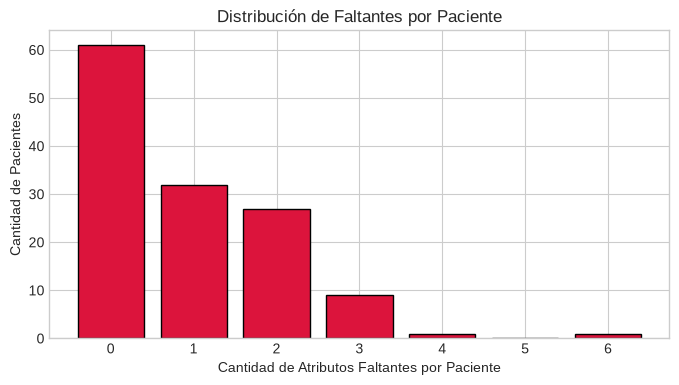

Pacientes con datos clínicos 100% completos: 61 (46.56%)


In [17]:
df_echo_hist = df_echo.copy()
cols_nulos = df_fl_echo_con_nulos['columna'].tolist()
df_echo_hist['cant_falt'] = df_echo[cols_nulos].isnull().sum(axis=1)

plt.figure(figsize=(8, 4))
plt.hist(df_echo_hist['cant_falt'], bins=np.arange(-0.5, 7.5, 1), rwidth=0.8, color='crimson', edgecolor='black')
plt.xlabel('Cantidad de Atributos Faltantes por Paciente')
plt.ylabel('Cantidad de Pacientes')
plt.title('Distribución de Faltantes por Paciente')
plt.xticks(range(7))
plt.show()

print(f"Pacientes con datos clínicos 100% completos: {(df_echo_hist['cant_falt'] == 0).sum()} ({(df_echo_hist['cant_falt'] == 0).mean()*100:.2f}%)")


## 4. Selección e Implementación del Método de Tratamiento

A partir del análisis de dominio y las pautas metodológicas de la cátedra:

Paso 1: Eliminación de Atributos No Relevantes (drop)
- name: identificador sin capacidad predictiva.
- group: clasificado explícitamente en la literatura médica como irrelevante / meaningless, con 22 valores faltantes.
- mult: variable derivada redundante recomendada para descartar.

Paso 2: Tratamiento Lógico y Censura de la Variable de Clase (alive_at_1)
- alive_at_1 posee 57 valores faltantes debido a pacientes con seguimiento menor a 1 año que seguían vivos al concluir el estudio (datos censurados a la derecha).
- Deducción determinística:
  - Si survival >= 12: el paciente sobrevivió al menos 12 meses -> alive_at_1 = 1.0 (recupera 44 casos).
  - Si survival < 12 y still_alive == 0: el paciente falleció antes del año -> alive_at_1 = 0.0 (recupera 2 casos).
- Los 11 casos restantes corresponden a censura estricta sin desenlace anual comprobable. Para clasificación supervisada, según la regla de cátedra (eliminar muestras cuando el faltante corresponde a la clase objetivo), se aíslan o descartan.

Paso 3: Imputación de Variables Fisiológicas Continuas
- Las variables predictoras numéricas (age_at_heart_attack, fractional_shortening, epss, lvdd, wall_motion_score, wall_motion_index) poseen entre 1 y 14 nulos (<11%).
- Al tratarse de variables cuantitativas continuas en pacientes con patologías cardiovasculares, la mediana es el método óptimo recomendado por la cátedra debido a su robustez frente a valores extremos y asimetrías.


In [18]:
# 1. Eliminación de atributos irrelevantes
df_echo_clean = df_echo.drop(columns=['name', 'group', 'mult'])
print("Dimensiones tras eliminar 'name', 'group' y 'mult':", df_echo_clean.shape)

# 2. Imputación lógica / determinística de la variable objetivo 'alive_at_1'
cond_vivo_al_ano = (df_echo_clean['alive_at_1'].isnull()) & (df_echo_clean['survival'] >= 12)
cond_fallecido_antes = (df_echo_clean['alive_at_1'].isnull()) & (df_echo_clean['survival'] < 12) & (df_echo_clean['still_alive'] == 0)

df_echo_clean.loc[cond_vivo_al_ano, 'alive_at_1'] = 1.0
df_echo_clean.loc[cond_fallecido_antes, 'alive_at_1'] = 0.0

print(f"Pacientes recuperados con supervivencia >= 12 meses: {cond_vivo_al_ano.sum()}")
print(f"Pacientes recuperados con fallecimiento < 12 meses:   {cond_fallecido_antes.sum()}")
print(f"Nulos restantes en 'alive_at_1' (censura real): {df_echo_clean['alive_at_1'].isnull().sum()}")
display(df_echo_clean['alive_at_1'].value_counts(dropna=False))


Dimensiones tras eliminar 'name', 'group' y 'mult': (131, 10)
Pacientes recuperados con supervivencia >= 12 meses: 44
Pacientes recuperados con fallecimiento < 12 meses:   2
Nulos restantes en 'alive_at_1' (censura real): 11


alive_at_1
1.0    68
0.0    52
NaN    11
Name: count, dtype: int64

In [19]:
# 3. Imputación de variables continuas por Mediana
predictores_num = [
    'survival',
    'age_at_heart_attack',
    'fractional_shortening',
    'epss',
    'lvdd',
    'wall_motion_score',
    'wall_motion_index'
]

df_echo_imputado = df_echo_clean.copy()

medianas = {}
for col in predictores_num:
    med = df_echo_imputado[col].median()
    medianas[col] = med
    df_echo_imputado[col] = df_echo_imputado[col].fillna(med)

print("Medianas aplicadas para imputación:")
for k, v in medianas.items():
    print(f"  - {k:<25}: {v:.3f}")

print("Total de nulos en predictores tras imputación por mediana:", df_echo_imputado[predictores_num].isnull().sum().sum())


Medianas aplicadas para imputación:
  - survival                 : 23.500
  - age_at_heart_attack      : 62.000
  - fractional_shortening    : 0.205
  - epss                     : 11.000
  - lvdd                     : 4.650
  - wall_motion_score        : 14.000
  - wall_motion_index        : 1.216
Total de nulos en predictores tras imputación por mediana: 0


### Comparación Gráfica Antes y Después de la Imputación (Ecocardiogramas)

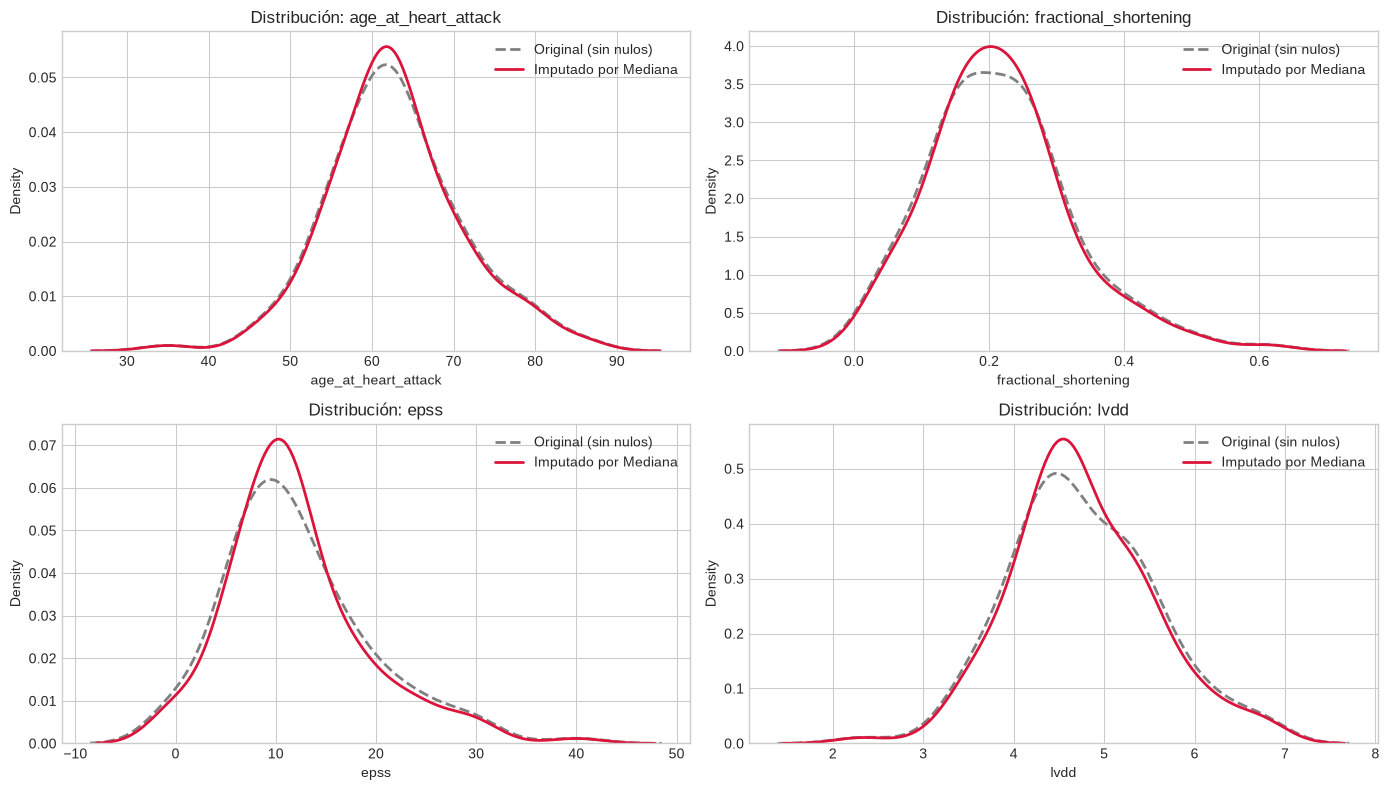

In [20]:
cols_a_comparar = ['age_at_heart_attack', 'fractional_shortening', 'epss', 'lvdd']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for idx, col in enumerate(cols_a_comparar):
    sns.kdeplot(df_echo_clean[col].dropna(), ax=axes[idx], label='Original (sin nulos)', color='gray', linestyle='--', linewidth=2)
    sns.kdeplot(df_echo_imputado[col], ax=axes[idx], label='Imputado por Mediana', color='crimson', linewidth=2)
    axes[idx].set_title(f'Distribución: {col}')
    axes[idx].legend()

plt.tight_layout()
plt.show()


### Conjunto de Datos Final para Clasificación Supervisada

In [21]:
# Para tareas de predicción, se descartan los 11 casos con etiqueta censurada (regla de cátedra)
df_echo_modelo = df_echo_imputado.dropna(subset=['alive_at_1']).copy()
df_echo_modelo['alive_at_1'] = df_echo_modelo['alive_at_1'].astype(int)

print(f"Dataset final listo para clasificación: {df_echo_modelo.shape[0]} pacientes x {df_echo_modelo.shape[1]} columnas")
print("Distribución de la clase objetivo (0 = No sobrevive al año, 1 = Sobrevive):")
display(df_echo_modelo['alive_at_1'].value_counts())


Dataset final listo para clasificación: 120 pacientes x 10 columnas
Distribución de la clase objetivo (0 = No sobrevive al año, 1 = Sobrevive):


alive_at_1
1    68
0    52
Name: count, dtype: int64

## 5. Justificación de la Elección (Ecocardiogramas)

1. Enfoque Híbrido según Naturaleza de Variables:
   - Variables Clínicas Predictoras (Numéricas Continuas): Se implementó imputación por mediana. Como se demostró en los gráficos de densidad KDE, la imputación por mediana preserva la morfología de la distribución original sin verse sesgada por valores atípicos de pacientes con insuficiencia cardíaca aguda (evitando errores sistemáticos en estimaciones de contractilidad como epss y fractional_shortening).

2. Deducción Determinística Previa a la Imputación:
   - Se aplicó conocimiento del dominio clínico para recuperar el desenlace de 46 pacientes cuya supervivencia acumulada permitía inferir objetivamente alive_at_1. Evita inventar datos y recupera más del 80% de los nulos de la clase.

3. Manejo de la Variable Objetivo Censurada (alive_at_1):
   - En conformidad con el principio metodológico de Valores Faltantes.ipynb ("Este método generalmente se utiliza cuando el valor faltante es el correspondiente a la clase"), para los 11 pacientes con seguimiento incompleto se opta por la eliminación de muestras en el dataset de modelado, previniendo sesgos de información y asignaciones arbitrarias de la etiqueta objetivo.

4. Eliminación de Columnas Irrelevantes:
   - Se eliminaron name, group y mult por carecer de valor estadístico y representar ruido innecesario en la base de datos.
